# Devoir 2 : Algorithme de Karger

### **1. Contexte**
Nous allons implémenter dans ce notebook un algorithme probabiliste pour estimer la coupe minimum d’un graphe. Le but de l'exercice est principalement de vous faire découvrir les algorithmes probabilistes, leurs avantages et d'en étudier la complexité. Pour certains problèmes, les algorithmes aléatoires sont préférables à des implémentations totalement déterministes, même s'ils ne garantissent pas toujours l'exactitude de la solution. L'algorithme de tri [Quicksort](https://en.wikipedia.org/wiki/Quicksort) est par exemple un algorithme de tri très efficace basé sur un choix de pivot aléatoire. Pour le problème de la coupe minimum d'un graphe, il existe l'algorithme de Karger que nous vous proposons d'implémenter dans ce notebook.

Une coupe d’un graphe est un ensemble d’arêtes déconnectant le graphe si elles sont toutes enlevées. La coupe minimum d’un graphe est donc la coupe qui minimise la somme des poids des arêtes (ou nombre d'arêtes dans un graphe non-pondéré, qui est le cas ici).

Ce problème est résolu dans ce notebook par l'algorithme de [Karger](https://en.wikipedia.org/wiki/Karger%27s_algorithm), que vous allez implémenter.

In [ ]:
import math
import time
import random
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

### **2. Algorithme**
#### **2.1 Description**
L'algorithme de Karger consiste à prendre à chaque étape une arête uniformément aléatoirement et la contracter. Par contraction, on entends la fusion des deux noeuds incidents à l'arête choisie. Les autres arêtes incidentes aux deux noeuds contractés sont toutes maintenues, il est donc possible d'obtenir des arêtes multiples si les deux noeuds fusionnés étaient adjacents au même noeud.

On répète la sélection aléatoire et la procédure de contraction jusqu’à ce qu’il ne reste plus que 2 noeuds dans le graphe. L’estimation de la coupe minimum est le nombre d’arêtes entre ces noeuds. L'observation cruciale est qu'une coupe dans le graphe contracté est aussi une coupe du graphe initial, la taille de la coupe minimum est donc préservée par contraction.

La figure ci dessous décrit une passe de l'algorithme de contraction qui trouve la coupe minimale dans un graphe à 10 noeuds. (source : [Wikipédia](https://en.wikipedia.org/wiki/Karger%27s_algorithm#/media/File:Single_run_of_Karger%E2%80%99s_Mincut_algorithm.svg))

Cet algorithme peut sembler très simple, mais il s’avère qu’il fonctionne bien en pratique. Intuitivement, lorsqu'on contracte une arête aléatoire du graphe, on a peu de chances de choisir une arête appartenant à la coupe minimale, car ces arêtes sont beaucoup moins nombreuses que les autres. Une minute de réflexion permet de voir que le sous-graphe formé de l’ensemble des arêtes contractées lors de ce processus forme une forêt sous-tendante à deux arbres, les sommets de chaque arbre étant ceux contractés en un seul sommet du graphe final à deux sommets. Le nombre d’arêtes du graphe séparant les arbres est l’estimation de la coupe minimum recherchée. Donc procéder à des contractions du graphe est équivalent à choisir des arêtes uniformément au hasard tout en évitant les cycles jusqu’à ce qu’elles forment une forêt à deux arbres, et ensuite de compter la coupe obtenue entre les deux arbres. Cependant, cette méthode reste naïve et est loin de fonctionner à tous les coups, il va falloir la réitérer pour améliorer l'estimation.



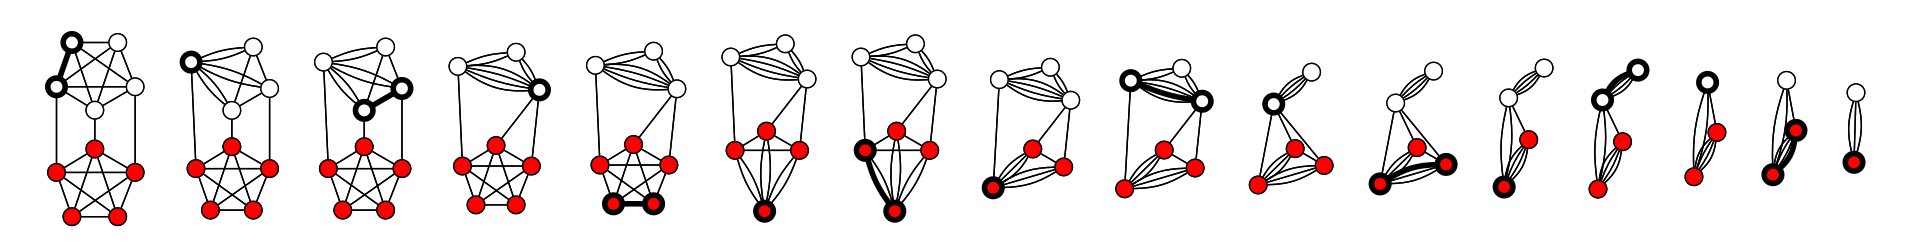

**Questions**

- Montrez une forme d'équivalence entre 1) cet algorithme et 2) l'algorithme de Kruskal appliqué après avoir pondéré toutes les arêtes aléatoirement.

**Réponses**

A COMPLETER.

#### **2.2 Probabilité de succès**

On cherche maintenant à borner inférieurement la probabilité de succès de l'algorithme de Karger. Pour cela, nous allons considérer une coupe minimale de taille $k$ dont l'ensemble des arêtes est noté $C$. On cherche la probabilité d'avoir $C$ à la fin de l'algorithme, c'est-à-dire qu'aucune de ses arêtes n'a été choisie lors de la phase de contraction.

Notons $E_i$ l'événement « l'arête contractée à l'étape $i$ n'appartient pas à $C$ ». On sait que l'algorithme de Karger effectue exactement $N-2$ contractions (il reste 2 noeuds à la fin de l'algorithme), on a donc
\begin{equation}
P(\text{succès}) = P(E_1)\cdot P(E_2 \mid E_1)\cdots P(E_{N-2} \mid E_1 \cap \dots \cap E_{N-3}).
\end{equation}

**Questions**
- Soit $m$ le nombre d'arêtes du graphe. Prouvez que $m \geq \frac{Nk}{2}$. (**Indice**: utilisez le lemme des poignées de mains).
- Utilisez le résultat précédent pour prouvez que $P(E_1) \geq \frac{N-2}{N}$.
- Ensuite, prouvez que $P(E_i \mid E_1 \cap \dots \cap E_{i-1}) \geq \frac{N-i-1}{N-i+1}$. (**Indice**: suivez le raisonnement appliqué aux deux points précédents).
- Utilisez le produit télescopique (1) pour trouver une borne inférieure $p$ à la probabilité de succès de l'algorithme de Karger.


**Réponses**

A COMPLETER.

**Question**

- En quoi le choix d'une coupe minimale en particulier (alors qu'il en existe plusieurs) et l'estimation du nombre d'arêtes par le théorème des poignées de mains mènent-ils à une sous-estimation de la probabilité de succès ? Nous verrons par la suite les conséquences d'une telle sous-estimation en pratique.

**Réponse**

A COMPLETER.

En pratique, on peut augmenter la probabilité de succès en répétant plusieurs fois l'algorithme de Karger (de manière indépendante à chaque essai), et en ne retenant que la meilleure solution.

**Questions**
- Si la probabilité succès d'une itération de Karger est $p$, combien de fois faut-il appliquer l'algorithme pour que la probabilité d'obtenir au moins une coupe minimum dépasse un certain niveau $\alpha \in [0, 1]$ ? Considérez un processus de Bernoulli où chaque expérience est indépendante avec une probabilité de succès de $p$.
- Utilisez vos réponses aux questions précédentes pour traduire ce résultat en un résultat sur la complexité du nombre d'itérations nécessaire pour atteindre le seuil $\alpha$ en fonction de la taille du graphe $N$. Utilisez aussi l'approximation de Taylor à l'ordre 1 du logarithme $\log(1-y) \approx -y$ pour $y \ll 1$.

**Réponses**

A COMPLETER.

Implémentez ci dessous la fonction qui calcule ce nombre d'itérations, en fonction de $N$.

In [ ]:
def get_iteration_number(N, alpha):
    """
    Retourne le nombre d'itération de Karger sur un graphe de taille N 
    nécessaires pour avoir une probabilité de succès qui dépasse alpha.
    """
    
    ## A COMPLETER ##
    p = ...
    T = ...

    return T 

### **3. Implémentation**



#### **3.1 Structure de données**

On va maintenant implémenter l'algorithme de Karger. En pratique, on maintient une partition de l'ensemble des noeuds du graphe, où chaque sous-ensemble contient les noeuds qui ont été fusionnés par une contraction d'arête. Les opérations les plus fréquentes à réaliser pendant l'exécution de l'algorithme sont la fusion de 2 sous-ensembles (lors d'une contraction) ainsi que la recherche du sous-ensemble auquel un sommet appartient (lorsque l'on veut contracter l'arête (a,b), il est utile de savoir à quels sous-ensembles appartiennent a et b). Une structure de données réalisant efficacement ces opérations s'appelle **Union-Find**. Vous trouverez ci-dessous une implémentation possible en Python sous forme d'une classe `Union_Find`.

In [ ]:
class Union_Find():
    """
    Structure de données pour l'Algorithme de Karger

    Utile pour retrouver le sous-ensemble du noeud a avec find(a)
    et fusionner les sous-ensembles des noeuds a et b avec union(a, b)
    """
    
    def __init__(self, N):
        """
        Initialise la structure de données
        INPUT :
            - N : le nombre initial de sous-ensembles
        """
        self.N = N              # Nombre de noeuds
        self.s = list(range(N)) # Indice du sous-ensemble auquel appartient chaque noeud
        self.size = [1]*N       # Taille de ce sous-ensemble
        self.n_subset = N       # Nombre de sous-ensembles
        
    def union(self, a, b):
        """
        INPUT :
            - a, b : 2 éléments tels que 0 <= a, b <= N-1
        OUTPUT:
            - None
            
        Fusionne les sous-ensembles de a et b
        """
        a = self.find(a)
        b = self.find(b)
       
        if a == b:
            return
       
        self.n_subset -= 1

        # Échange les variable si nécessaire
        if self.size[a] > self.size[b]:
            a,b = b,a
        
        self.size[b] += self.size[a]
        self.s[a] = b
        
    def find(self, a):
        """
        INPUT :
            - a : un noeud tel que 0 <= a <= N-1
        OUTPUT:
            - retourne la racine du sous-ensemble de a 
              et rattache a à cette racine pour accélérer 
              la recherche à la prochaine itération (complexité amortie)
        """
        if a != self.s[a]:
            self.s[a] = self.find(self.s[a])
        return self.s[a]


**Questions**

- Sous quelle forme est stockée l'information dans l'implémentation `Union_Find` ? Quelle est la taille en mémoire de cette structure de données, en fonction de $N$ ?

- Quelle est la complexité des opérations `find` et `union` dans le pire des cas ? (**Indice**: observez que lorsqu'un noeud devient un enfant d'une autre racine lors d'une fusion, la taille de son sous-ensemble au moins double. Déduisez-en le parcours le plus long d'un noeud vers sa racine dans un sous-ensemble de taille $t$).

**Réponses**

A COMPLETER.

En réalité, il est possible de montrer que la complexité amortie d'une opération `find` est en $\mathcal{O}(\alpha(N))$, où $\alpha$ est la [fonction inverse d'Ackermann](https://fr.wikipedia.org/wiki/Fonction_d%27Ackermann). Celle-ci croît extrêmement lentement et reste inférieure à 5 pour les tailles de données rencontrées en pratique, si bien que vous pouvez considérer qu'une opération `find` coûte $\mathcal{O}(1)$ pour le reste de l'étude de complexité.

(**Note**: pour les plus curieux, ce résultat est dû à la [compression de chemin](https://fr.wikipedia.org/wiki/Union-find#Am%C3%A9lioration_de_find_avec_la_compression_de_chemin) réalisé par la fonction `find`: à chaque appel à find, on aplatit l'arbre de dépendance des noeuds en rattachant le noeud directement à sa racine -- il en va de même pour tous les noeuds par lesquels on a du remonter. Dès lors, sans fusion supplémentaire, le prochain appel s'effectue en $\mathcal{O}(1)$).

#### **3.2 Représentation du graphe**

Pour cet algorithme, nous fournirons le graphe sous la forme d'un nombre de noeuds $N$ et d'une liste d'arêtes, chaque arête étant un couple $(u,v)$ avec $u, v \in \{0, N-1\}$. Cela facilitera l'itération aléatoire sur les arêtes. Notez cependant que si l'on dispose uniquement d'une matrice d'adjacence (ou d'une liste d'adjacence) et que l'on doit réaliser la conversion vers la représentation en liste d'arêtes, cela induit un coût en $\mathcal{O}(N^2)$ (ou en $\mathcal{O}(E)$, respectivement). Nous verrons l'importance de ce coût lors de l'étude de complexité. Exécutez la cellule ci-dessous pour visualiser l'exemple donné.

In [ ]:
G = (8, [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3), (4, 5), (4, 6), (4, 7), (5, 6), (5, 7), (6, 7), (0, 4), (1, 5)])

In [ ]:
n, edges = G
g = nx.Graph()
g.add_nodes_from(range(n))
g.add_edges_from(edges)
 
nx.draw(g, with_labels=True, node_color="lightblue", node_size=600)
plt.show()

#### 3.3 **Algorithme complet**

Passez maintenant à l'implémentation de l'algorithme de Karger, en veillant à utiliser intelligemment la classe `Union_Find`. Pour être plus précis, implémentez une fonction `karger` qui exécute une fois l'algorithme de Karger et retourne la taille de la coupe trouvée, et une fonction `min_cut` qui répète $t$ fois l'algorithme de Karger, où $t$ est calculé sur base d'une probabilité de succès $\alpha$ à atteindre, et retourne la taille de la plus petite coupe trouvée. Dans la suite du notebook, on fera référence à ce deuxième algorithme par 'l'algorithme min-cut'.

In [ ]:
def karger(N, edges):
    """
        INPUT :
            - N,     le nombre de noeuds
            - edges, liste de tuples (u, v) décrivant une arête entre u et v
        OUTPUT :
            - retourne une estimation de la taille de la coupe minimum
        """
    
    ## A COMPLETER ##
    min_cut_estimate = ...

    return min_cut_estimate

def min_cut(N, edges, alpha=0.95, n_iter=None):
    """
    INPUT :
        - N,      le nombre de noeuds
        - edges,  liste de tuples (u, v) décrivant une arête entre u et v
        - alpha,  seuil de succès demandé
        - n_iter, possibilité de fixer le nombre d'itérations sans utiliser le paramètre alpha

    OUTPUT :
        - retourne une estimation de la taille de la coupe minimum, 
          avec probabilité de succès supérieure à alpha
    """

    best_min_cut = len(edges)
    if n_iter is None:
        n_iter = get_iteration_number(N, alpha)

    ## A COMPLETER ##
    best_min_cut = ...
    
    return best_min_cut

### **4 Evaluation de l'algorithme**

#### **4.1 Complexité**

**Questions théoriques**

- Quelle est la complexité de l'algorithme de Karger, et de l'algorithme min-cut, exprimée en terme du nombre d'opérations `union` et `find` ? En utilisant la complexité de `union` et `find`, trouvez la complexité en terme de $|E|=m$ et $|V|=N$.

- La traduction du graphe vers une liste d'arêtes est-elle significative par rapport à l'exécution de l'algorithme ?

**Réponses**

A COMPLETER.

#### **4.2 Expériences numériques**

La cellule suivantes définit des graphes utilisés pour évaluer les performances de votre implémentation de l'algorithme de Karger.

- Deux cliques reliées par $d$ arêtes => min_cut = d.
- Un cycle dont tous les arêtes sont multiples, avec $d$ copies sauf pour deux arêtes avec $d-1$ copies => min_cut = $2(d-1)$.
- Un ensemble de cliques de taille $2d+1$, chacune reliée au deux cliques voisines par $d$ arêtes (les cliques forment un cycle) => min_cut = $2d$.

In [ ]:
def d_connected_cliques(n, d=6):
    h = n//2
    if h < d+1:
        raise ValueError("Require n >= 2*d + 2")
    a = nx.complete_graph(h)
    b = nx.relabel_nodes(nx.complete_graph(h), lambda i: i+h)
    g = nx.compose(a, b)
    for i in range(d):
        g.add_edge(i, h + i)
    return 2*h, list(g.edges()), d

def fat_cycle(n, d=4):
    edges = []
    for i in range(n):
        mult = d - 1 if i in (0, n // 2) else d
        edges += [(i, (i + 1) % n)] * mult
    return n, edges, 2*(d-1)

def chain_of_cliques(n, d=3):
    clique_size = 2*d + 1
    n_cliques = n // clique_size
    if n_cliques < 2:
        raise ValueError("Require n >= 4*d + 2")
    
    cliques = []
    for i in range(n_cliques):
        a = nx.relabel_nodes(nx.complete_graph(clique_size), lambda j: j+i*clique_size)
        cliques.append(a)
    g = nx.compose_all(cliques)

    for i in range(n_cliques - 1):
        for j in range(d):
            g.add_edge(d + 1 + i*clique_size + j, (i+1)*clique_size + j)
    for j in range(d):
        g.add_edge(d + 1 + (n_cliques-1)*clique_size + j, j)
    
    return n_cliques*clique_size, list(g.edges()), 2*d

La cellule ci-dessous exécute l'algorithme de Karger et l'algorithme min-cut sur les différents graphes et compare les temps d'exécution. Faites la tourner et commentez les résultats.

In [ ]:
alpha = 0.3

def one_run(n, graph=d_connected_cliques, reps=100):
    """
    Mesure le temps d'exécution moyen d'une itération de l'algorithme de Karger.

    INPUT :
        n     : nombre de sommets souhaité dans le graphe
        graph : fonction qui génère le graphe
        reps  : nombre de répétitions de l'algorithme

    OUTPUT :
        Temps moyen d'une exécution de Karger, en secondes
    """
    n, edges, true_min_cut = graph(n)
    t = time.perf_counter()
    for _ in range(reps):
        karger(n, edges)
    return (time.perf_counter() - t) / reps

    
def total_run(n, graph=d_connected_cliques, reps=5):
    """
    Mesure le temps d'exécution moyen de l'algorithme min_cut,
    qui peut effectuer plusieurs exécutions de Karger.

    INPUT :
        n     : nombre de sommets souhaité dans le graphe
        graph : fonction qui génère le graphe
        reps  : nombre de répétitions de min_cut

    OUTPUT :
        Temps moyen d'une exécution complète de min_cut, en secondes
    """
    n, edges, true_min_cut = graph(n)
    t = time.perf_counter()
    for _ in range(reps):
        min_cut(n, edges, alpha=alpha)
    return (time.perf_counter() - t) / reps


def fit_loglog(x, y):
    log_x = np.log10(x)
    log_y = np.log10(y)
    slope, intercept = np.polyfit(log_x, log_y, 1)
    fit = 10 ** (slope * log_x + intercept)
    return fit, slope

sizes = np.geomspace(40,400,6,dtype=int)
t_cliques = [one_run(k, graph=d_connected_cliques) for k in sizes]
t_cycles = [one_run(k, graph=fat_cycle) for k in sizes]
t_chain = [one_run(k, graph=chain_of_cliques) for k in sizes]
fit, slope_cliques = fit_loglog(sizes, t_cliques)
plt.loglog(sizes, fit, c="C0", label=f"cliques, pente={slope_cliques:.2f}")
plt.loglog(sizes, t_cliques, 'o', c="C0")
fit, slope_cycles = fit_loglog(sizes, t_cycles)
plt.loglog(sizes, fit, c="C1", label=f"cycles, pente={slope_cycles:.2f}")
plt.loglog(sizes, t_cycles, 'o', c="C1")
fit, slope_chain = fit_loglog(sizes, t_chain)
plt.loglog(sizes, fit, c="C2", label=f"clique-chain, pente={slope_chain:.2f}")
plt.loglog(sizes, t_chain, 'o', c="C2")
plt.legend()
plt.xlabel("Taille du graphe N")
plt.ylabel("Temps [s]")
plt.title("Complexité d'une itération de Karger (log-log)")
plt.show()

sizes = np.geomspace(40,120,4,dtype=int)
t_cliques = [total_run(k, graph=d_connected_cliques) for k in sizes]
t_cycles = [total_run(k, graph=fat_cycle) for k in sizes]
t_chain = [total_run(k, graph=chain_of_cliques) for k in sizes]
fit, slope_cliques = fit_loglog(sizes, t_cliques)
plt.loglog(sizes, fit, c="C0", label=f"cliques, pente={slope_cliques:.2f}")
plt.loglog(sizes, t_cliques, 'o', c="C0")
fit, slope_cycles = fit_loglog(sizes, t_cycles)
plt.loglog(sizes, fit, c="C1", label=f"cycles, pente={slope_cycles:.2f}")
plt.loglog(sizes, t_cycles, 'o', c="C1")
fit, slope_chain = fit_loglog(sizes, t_chain)
plt.loglog(sizes, fit, c="C2", label=f"clique-chain, pente={slope_chain:.2f}")
plt.loglog(sizes, t_chain, 'o', c="C2")
plt.legend()
plt.xlabel("Taille du graphe N")
plt.ylabel("Temps [s]")
plt.title("Complexité totale de l'algorithme min-cut (log-log)")
plt.show()

**Questions**

- Observez vous une différence entre la complexité d'une itération de Karger entre le graphe constitué de 2 cliques et les deux autres graphes ? Pourquoi y'a-t-il environ un ordre de grandeur entre ces deux courbes ? Regardez le nombre d'arêtes en fonction de la taille de chaque graphe.

- Quelle est complexité totale observée en fonction de la taille de chaque graphe ? Comparez à la complexité calculée comme le produit du nombre d'itérations de Karger nécessaires par la complexité d'une itération.

**Réponses**

A COMPLETER.

#### **4.2 Taux de succès**

Afin de vérifier empiriquement le taux de succès de votre algorithme, la cellule suivante fait tourner un certains nombre d'itérations de Karger sur les 3 différents graphes, et évalue son taux de succès.

In [ ]:
def evaluate(graph=d_connected_cliques, nreps=100):
    """
    Estime expérimentalement la probabilité de succès de Karger
    en fonction du nombre d'itérations effectuées.

    INPUT :
        graph : fonction qui génère un graphe et fournit sa coupe minimale
        nreps : nombre d'expériences indépendantes réalisées pour chaque taille

    OUTPUT :
        results : liste de tableaux contenant les probabilités de succès
                  estimées pour chaque taille et chaque nombre d'itérations
    """
    results = []
    for size in sizes:
        n, edges, real_min_cut = graph(size)
        success_per_iterations = np.zeros(nb_iterations)
        for _ in range(nreps):
            found_cut = karger(n, edges)
            nb_iter_needed = 1
            while found_cut != real_min_cut and nb_iter_needed < nb_iterations:
                found_cut = karger(n, edges)
                nb_iter_needed += 1
            success_per_iterations[nb_iter_needed:] += 1
        results.append(success_per_iterations / nreps)
    return results


sizes = [20, 40, 60]
nb_iterations = 600
tested_iterations = np.arange(0, nb_iterations)
probas = np.linspace(0,0.975,50)
predicted_nb_iterations = [[get_iteration_number(sizes[i],probas[j]) for j in range(len(probas))] for i in range(len(sizes))]

results_chain = evaluate(graph=chain_of_cliques)
results_cliques = evaluate(graph=d_connected_cliques)
results_cycles  = evaluate(graph=fat_cycle)


fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)

datasets = [
    (results_cycles,  "cycle"),
    (results_cliques, "cliques"),
    (results_chain,   "clique-chain"),
]

for ax, (results, name) in zip(axes, datasets):
    for i, size in enumerate(sizes):
        ax.plot(tested_iterations, results[i],color=f"C{i}", label=f"Expérimentale, n={size}")
        ax.plot(predicted_nb_iterations[i],probas,":",color=f"C{i}", label=f"Borne calculée, n={size}")

    ax.set_xlim([0,600])
    ax.set_xlabel("nb_iterations")
    ax.set_title(name)
    ax.legend()

axes[0].set_ylabel("Probabilité de succès")
fig.suptitle("Probabilité de succès pour un certain nombre d'itérations, pour 3 tailles de graphe")
plt.tight_layout()
plt.show()

**Question**

- On constate que le nombre moyen d'itérations nécessaires pour arriver à une coupe minimum est inférieur (parfois même très inférieur) au seuil calculé initialement. Ceci avait déjà été prédit en section 2.2, où l'on avait observé que notre preuve ne prenait pas en compte la potentielle présence de plusieurs coupes minimum, et sous-estimait le nombre total d'arêtes dans le graphe (à chaque étape) et donc sur-estimait la probabilité de tirer une arête de la coupe minimum. Discutez de ceux deux effets pour les trois types de graphes étudiés, et expliquez la différence de performance de l'algorithme. Pourquoi le nombre d'itérations nécessaires varie t-il autant d'un type de graphe à l'autre ?

**Réponse**

A COMPLETER.